# 08 · PD Model: WOE Logistic Regression

**Objective:** fit a probability-of-default model on the eight WOE features from notebook 07, validate it in time and out of time, and benchmark it against LendingClub's own grade.

**Bottom line:** **with eight application-time features, a WOE logistic regression reaches about 90% of the Gini of LendingClub's grade and holds up out of time.** Out-of-time AUC 0.655 / Gini 0.31 / KS 0.22 vs. grade's Gini 0.34. No overfitting (train 0.649 vs. validation 0.647 AUC), and every coefficient has the expected negative sign. **Calibration drifted**: predicted PD 14.2% vs. an actual 14.7% out of time, consistent with the 2015 population drift, so the intercept should be recalibrated on recent data.

In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from lending_db import get_connection, IMAGE_DIR

con = get_connection()
pd.set_option("display.max_columns", None)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from lending_db import DATA_DIR

## 1. Samples
| Sample | Definition | Purpose |
|---|---|---|
| Train | Development period (Jan-2014 to Jun-2015), random 80%, stratified on `bad_flag` | Fit |
| Validation | Development period, random 20% | Overfitting check |
| Out-of-time (OOT) | Jul–Dec 2015 | Performance on a later, unseen period |

In [2]:
model = con.sql(f"SELECT * FROM '{DATA_DIR / 'model_woe.parquet'}'").df()
model = model[model["bad_flag"].notna()]                      # drop the 86 indeterminate loans
woe_cols = [c for c in model.columns if c.endswith("_woe")]

dev = model[model["issue_date"] < "2015-07-01"]
oot = model[model["issue_date"] >= "2015-07-01"]
train, val = train_test_split(dev, test_size=0.2, random_state=42, stratify=dev["bad_flag"])

pd.DataFrame({name: {"loans": len(d), "bad_rate": d["bad_flag"].mean()}
              for name, d in [("train", train), ("validation", val), ("oot", oot)]}).T.round(4)

,loans,bad_rate
train,226688.0,0.1432
validation,56672.0,0.1432
oot,162297.0,0.1474


## 2. Fit and coefficient check
With WOE = ln(good share / bad share), a higher WOE means lower risk, so **every coefficient must be negative**. A positive sign would point to multicollinearity or a redundant feature.

In [3]:
lr = LogisticRegression(max_iter=1000).fit(train[woe_cols], train["bad_flag"])

coef = (pd.DataFrame({"feature": [c.removesuffix("_woe") for c in woe_cols], "coefficient": lr.coef_[0]})
          .sort_values("coefficient"))
assert (coef["coefficient"] < 0).all(), "every WOE coefficient should be negative"
print(f"intercept: {lr.intercept_[0]:.3f}  ->  PD at average risk (all WOE = 0): {1 / (1 + np.exp(-lr.intercept_[0])):.1%}")
coef.round(3)

intercept: -1.795  ->  PD at average risk (all WOE = 0): 14.2%


,feature,coefficient
6,purpose,-0.839
0,fico_range_low,-0.832
2,dti,-0.764
3,inq_last_6mths,-0.730
4,home_ownership,-0.659
1,annual_inc,-0.595
5,verification_status,-0.553
7,emp_length,-0.403


The intercept implies a PD of 14.2% for a borrower who is average on every feature, essentially the portfolio bad rate (14.3%).

## 3. Discrimination
* **AUC**: probability that a random bad borrower gets a higher PD than a random good one (0.5 = random).
* **Gini** = 2 × AUC − 1.
* **KS**: largest gap between the cumulative shares of bads and goods when borrowers are sorted by PD.

In [4]:
def ks_stat(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return (tpr - fpr).max()


rows = []
for name, d in [("train", train), ("validation", val), ("oot", oot)]:
    p = lr.predict_proba(d[woe_cols])[:, 1]
    auc = roc_auc_score(d["bad_flag"], p)
    rows.append({"sample": name, "AUC": auc, "Gini": 2 * auc - 1, "KS": ks_stat(d["bad_flag"], p),
                 "avg_PD": p.mean(), "bad_rate": d["bad_flag"].mean()})

# Benchmark: LendingClub's grade on the same out-of-time loans (A = 0 ... G = 6)
grade = con.sql("""
SELECT grade, bad_flag FROM cohort
WHERE issue_date >= '2015-07-01' AND bad_flag IS NOT NULL
""").df()
grade_score = grade["grade"].map({g: i for i, g in enumerate("ABCDEFG")})
auc_g = roc_auc_score(grade["bad_flag"], grade_score)
rows.append({"sample": "oot: grade (benchmark)", "AUC": auc_g, "Gini": 2 * auc_g - 1,
             "KS": ks_stat(grade["bad_flag"], grade_score)})

metrics = pd.DataFrame(rows)
metrics.round(4)

,sample,AUC,Gini,KS,avg_PD,bad_rate
0,train,0.6489,0.2979,0.2149,0.1432,0.1432
1,validation,0.6468,0.2937,0.2120,0.1428,0.1432
2,oot,0.6551,0.3102,0.2223,0.1418,0.1474
3,oot: grade (benchmark),0.6700,0.3400,0.2660,NaN,NaN


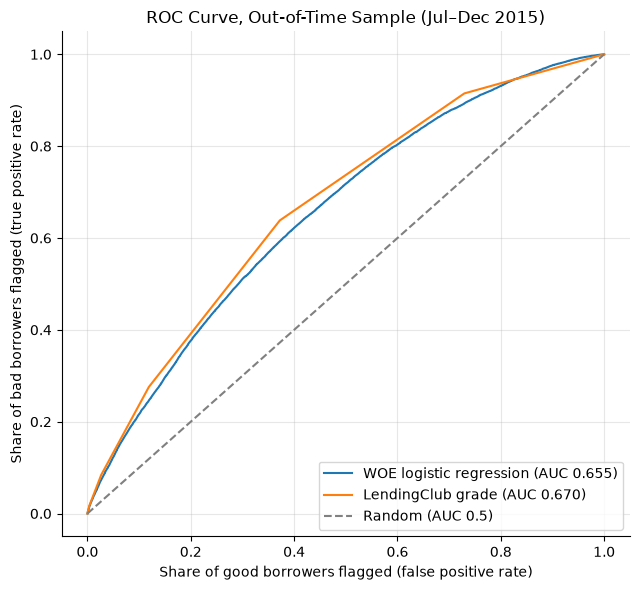

In [5]:
p_oot = lr.predict_proba(oot[woe_cols])[:, 1]
fig, ax = plt.subplots(figsize=(6.5, 6))
for label, y, score in [("WOE logistic regression", oot["bad_flag"], p_oot),
                        ("LendingClub grade", grade["bad_flag"], grade_score)]:
    fpr, tpr, _ = roc_curve(y, score)
    ax.plot(fpr, tpr, label=f"{label} (AUC {roc_auc_score(y, score):.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random (AUC 0.5)")
ax.set_title("ROC Curve, Out-of-Time Sample (Jul–Dec 2015)")
ax.set_xlabel("Share of good borrowers flagged (false positive rate)")
ax.set_ylabel("Share of bad borrowers flagged (true positive rate)")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(IMAGE_DIR / "roc_oot.png", dpi=150)
plt.show()

* **No overfitting:** train and validation AUC differ by 0.002, as expected for eight binned features.
* **Stable out of time:** OOT discrimination is as good as in development.
* **Benchmark:** grade's Gini is 0.34; the model reaches 0.31 (≈ 91%) with eight public application fields. Grade draws on full bureau data, platform data and years of history, so the gap is expected.

## 4. Calibration
Discrimination asks whether the **ranking** is right; calibration asks whether the **PD level** is right. Compare predicted and actual bad rates by PD decile.

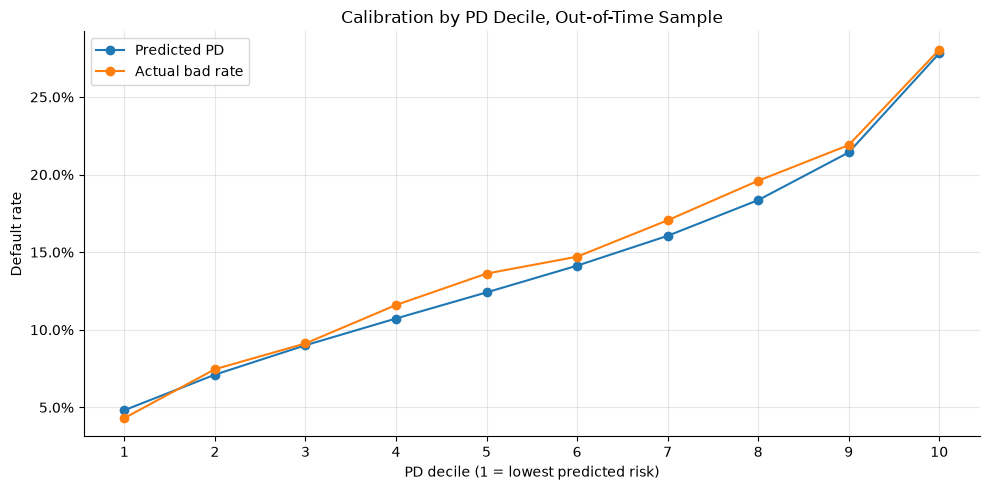

OOT average: predicted 14.18% vs. actual 14.74%


,predicted,actual,loans
decile,,,
1,0.0482,0.0431,16239
2,0.0711,0.0746,16221
3,0.0900,0.0912,16229
4,0.1073,0.1160,16256
5,0.1241,0.1362,16211
6,0.1413,0.1471,16222
7,0.1605,0.1705,16230
8,0.1835,0.1960,16233
9,0.2143,0.2190,16227


In [6]:
cal = pd.DataFrame({"pd": p_oot, "bad": oot["bad_flag"].to_numpy()})
cal["decile"] = pd.qcut(cal["pd"], 10, labels=False) + 1
by_decile = cal.groupby("decile").agg(predicted=("pd", "mean"), actual=("bad", "mean"), loans=("bad", "size"))

fig, ax = plt.subplots()
ax.plot(by_decile.index, by_decile["predicted"], marker="o", label="Predicted PD")
ax.plot(by_decile.index, by_decile["actual"], marker="o", label="Actual bad rate")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xticks(range(1, 11))
ax.set_title("Calibration by PD Decile, Out-of-Time Sample")
ax.set_xlabel("PD decile (1 = lowest predicted risk)")
ax.set_ylabel("Default rate")
ax.legend()
fig.tight_layout()
fig.savefig(IMAGE_DIR / "calibration_oot.png", dpi=150)
plt.show()

print(f"OOT average: predicted {p_oot.mean():.2%} vs. actual {oot['bad_flag'].mean():.2%}")
by_decile.round(4)

* Actual bad rates rise steadily from the lowest to the highest decile, so the **ranking works**.
* The model **under-predicts on average** (14.2% vs. 14.7%), matching the 2015 population drift found in notebook 06: borrowers with the same profile defaulted more. Because discrimination held, the remedy is to **recalibrate the intercept** on recent data, not to rebuild.

## 5. Next steps
* Recalibrate the intercept on the most recent vintages and monitor calibration over time.
* Add bureau features (credit history length, account counts, public records) and fit a gradient-boosting **challenger** against this champion and grade.
* Convert coefficients into scorecard points for interpretability and adverse-action reasons.